# 3.3 — LoRA on a small open model
**Session 3.3 · Demo**

**Before you run:** choose Runtime > Change runtime type > T4 GPU.

What you'll see: a small open model fine-tuned with LoRA to classify support messages, in under
15 minutes, then compared with prompting the same model and with Claude Haiku.


In [1]:
# @title Setup: install the fine-tuning tools and connect to Claude { display-mode: "form" }
import importlib, importlib.util, shutil, subprocess, sys
# uv comes with Colab and installs much faster than pip; pip is the fallback.
INSTALL = (["uv", "pip", "install", "--python", sys.executable, "-q"] if shutil.which("uv")
           else [sys.executable, "-m", "pip", "install", "-q"])
required = {
    "anthropic": "anthropic", "peft": "peft", "datasets": "datasets",
    "bitsandbytes": "bitsandbytes", "accelerate": "accelerate",
}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([*INSTALL, *missing])
    importlib.invalidate_caches()

import html
import os
import time
from concurrent.futures import ThreadPoolExecutor
from getpass import getpass

import anthropic
import torch
from datasets import load_dataset
from IPython.display import HTML, display
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, Trainer, TrainingArguments

# SMOKE=1 trains for a few steps on CPU, to test the notebook without a GPU.
SMOKE = os.environ.get("SMOKE") == "1"
HAS_GPU = torch.cuda.is_available()
if not HAS_GPU and not SMOKE:
    raise RuntimeError("This notebook needs a GPU. Choose Runtime > Change runtime type > T4 GPU.")


def read_api_key():
    """Environment variable, then the Colab secret, then a prompt. The key is never printed."""
    key = os.environ.get("ANTHROPIC_API_KEY")
    if key:
        return key
    try:
        from google.colab import userdata
        return userdata.get("ANTHROPIC_API_KEY")
    except Exception:
        return getpass("Paste your Anthropic API key: ")


client = anthropic.Anthropic(api_key=read_api_key())

# Display helpers, so the results read well on a shared screen.
INK, SOFT_INK, BLUE, ORANGE, AQUA = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#1baf7a"
GREY, GRID, SURFACE = "#898781", "#e1e0d9", "#fcfcfb"


def text_html(text):
    return html.escape(str(text)).replace("\n", "<br>")


def badge(text, colour=BLUE):
    return (f'<span style="display:inline-block;margin:2px;padding:2px 9px;border-radius:10px;background:{colour};'
            f'color:#fff;font-size:12px;font-weight:600">{html.escape(str(text))}</span>')


def card(title, body_html, colour=BLUE):
    """A white box with a coloured left edge."""
    title_html = f'<div style="font-size:12px;color:{SOFT_INK};margin-bottom:4px">{html.escape(title)}</div>' if title else ""
    return (f'<div style="margin:6px 0;padding:8px 12px;border-left:3px solid {colour};background:#fff;color:{INK}">'
            f"{title_html}{body_html}</div>")


def name_label(what, name, url):
    """A model's or a dataset's name, linked to its page."""
    return (f'<span style="display:inline-block;margin:2px 6px 6px 0;padding:3px 10px;border-radius:12px;'
            f'background:#eef3fb;border:1px solid {BLUE};color:{INK};font-size:12.5px">{html.escape(what)}: '
            f'<a href="{url}" target="_blank" style="color:{BLUE};font-weight:600;text-decoration:none">'
            f'{html.escape(name)}</a></span>')


def big_number(number, text, detail=""):
    """A headline figure: a big number, what it means, and a grey detail line."""
    detail_html = f'<div style="font-size:13px;color:{SOFT_INK};margin-top:4px">{html.escape(detail)}</div>' if detail else ""
    display(HTML(
        f'<div style="margin:8px 0;padding:10px 14px;background:#fff;border-left:3px solid {BLUE}">'
        f'<span style="font-size:30px;font-weight:700;color:{BLUE}">{html.escape(number)}</span> '
        f'<span style="font-size:17px;color:{INK}">{html.escape(text)}</span>{detail_html}</div>'
    ))


def side_by_side(columns):
    """Cards in columns: {column title: (body html, colour)}."""
    cells = "".join(
        f'<td style="vertical-align:top;padding:0 6px;width:{100 // len(columns)}%">{card(title, body, colour)}</td>'
        for title, (body, colour) in columns.items()
    )
    display(HTML(f'<table style="border-collapse:collapse;width:100%"><tr>{cells}</tr></table>'))


gpu_name = torch.cuda.get_device_name(0) if HAS_GPU else "none (smoke test)"
display(HTML(card("", f"Ready. GPU: <b>{html.escape(gpu_name)}</b>")))

In [2]:
# @title Answer caching { display-mode: "form" }
# @markdown When this is on, a request that is exactly the same as one already sent gets the saved answer
# @markdown back. Untick it (and run this step) to get fresh answers from the model.
REPLAY = True  # @param {type:"boolean"}

import hashlib
import json
import os
from contextlib import contextmanager

import anthropic
from anthropic.resources.messages import Messages

REPLAY_DIR = "/content/claude_replay" if os.path.isdir("/content") else os.path.expanduser("~/claude_replay")
os.makedirs(REPLAY_DIR, exist_ok=True)
if not hasattr(Messages, "live_create"):
    Messages.live_create = Messages.create  # The real call, kept so we can switch back.
replay_count = {"saved answers reused": 0, "new calls": 0}


def replay_create(self, **request):
    """Every call to the model comes through here: reuse a saved answer, or call the model and save the answer."""
    # The connection type and address are part of the key, so a simulated outage never gets a saved answer,
    # and a local model never gets one of Claude's.
    connection = type(getattr(getattr(self._client, "_client", None), "_transport", None)).__name__
    address = str(self._client.base_url)
    key = hashlib.sha256(json.dumps([connection, address, request], sort_keys=True, default=str).encode()).hexdigest()
    path = os.path.join(REPLAY_DIR, f"{key}.json")
    if os.path.exists(path):
        replay_count["saved answers reused"] += 1
        with open(path) as file:
            return anthropic.types.Message.model_validate_json(file.read())
    response = Messages.live_create(self, **request)
    if isinstance(response, anthropic.types.Message):  # Streamed replies aren't saved.
        with open(path, "w") as file:
            file.write(response.model_dump_json())
    replay_count["new calls"] += 1
    return response


Messages.create = replay_create if REPLAY else Messages.live_create


@contextmanager
def fresh_answers():
    """Inside this block, every request goes to the model, even with saved answers on. Used for timings."""
    current = Messages.create
    Messages.create = Messages.live_create
    try:
        yield
    finally:
        Messages.create = current


saved = len(os.listdir(REPLAY_DIR))
print(f"Saved answers {'on' if REPLAY else 'off'}. {saved} saved so far in {REPLAY_DIR}.")

Saved answers on. 0 saved so far in /content/claude_replay.


## 1. Load a small open instruct model
Qwen2.5-0.5B. On the GPU it loads in 4-bit, which is the "Q" in
QLoRA: each number is stored in 4 bits instead of 16, so the model takes far less memory.

In [3]:
# @title Load Qwen2.5-0.5B in 4-bit { display-mode: "form" }
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, padding_side="left")
if HAS_GPU:
    quantization = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
    )
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=quantization, device_map="auto")
else:
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)

display(HTML(name_label("Base model", MODEL_NAME, f"https://huggingface.co/{MODEL_NAME}")))
big_number(f"{model.get_memory_footprint() / 1e9:.2f} GB", "of memory for the whole model",
           f"{MODEL_NAME}, {'4-bit on the GPU' if HAS_GPU else 'full size on the CPU (smoke test)'}")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## 2. Fine-tune on about 500 examples
The data is the public Bitext customer-support dataset. The task: read a message and name its
category. We hold out a test set that training never sees.

In [7]:
# @title The data: customer messages and their categories { display-mode: "form" }
DATASET = "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
dataset = load_dataset(DATASET, split="train")
frame = dataset.to_pandas()[["instruction", "category"]].drop_duplicates("instruction")

TRAIN_SIZE, TEST_SIZE = (16, 8) if SMOKE else (500, 200)
CATEGORIES = sorted(frame["category"].unique())
shuffled = frame.sample(frac=1, random_state=42).reset_index(drop=True)
train = shuffled.iloc[:TRAIN_SIZE]
test = shuffled.iloc[TRAIN_SIZE:TRAIN_SIZE + TEST_SIZE]

display(HTML(name_label("Data", DATASET, f"https://huggingface.co/datasets/{DATASET}")))
big_number(str(len(train)), "training examples",
           f"plus {len(test)} test examples, across {len(CATEGORIES)} categories")
display(HTML(
    f'<div style="margin:4px 0 10px">{"".join(badge(category, GREY) for category in CATEGORIES)}</div>'
    + "".join(
        card("A training example", f'{text_html(row["instruction"])}<div style="margin-top:6px">→ {badge(row["category"])}</div>')
        for _, row in train.head(3).iterrows()
    )
))

In [8]:
# @title Turn each example into training text { display-mode: "form" }
TASK = f"Classify this customer message into one category: {', '.join(CATEGORIES)}. Reply with the category only."


def prompt_ids(messages):
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return tokenizer(text, add_special_tokens=False).input_ids


def to_features(row):
    """Tokenize one example. Labels are -100 on the prompt, so only the answer trains the model."""
    prompt = prompt_ids([{"role": "user", "content": f"{TASK}\n\nMessage: {row['instruction']}"}])
    answer = tokenizer(f"{row['category']}<|im_end|>", add_special_tokens=False).input_ids
    return {
        "input_ids": prompt + answer,
        "attention_mask": [1] * (len(prompt) + len(answer)),
        "labels": [-100] * len(prompt) + answer,
    }


train_features = [to_features(row) for _, row in train.iterrows()]


def collate(batch):
    """Pad every example in a batch to the same length."""
    width = max(len(item["input_ids"]) for item in batch)
    padded = {"input_ids": [], "attention_mask": [], "labels": []}
    for item in batch:
        gap = width - len(item["input_ids"])
        padded["input_ids"].append(item["input_ids"] + [tokenizer.pad_token_id] * gap)
        padded["attention_mask"].append(item["attention_mask"] + [0] * gap)
        padded["labels"].append(item["labels"] + [-100] * gap)
    return {key: torch.tensor(value) for key, value in padded.items()}


# One example as the model sees it: the prompt it reads, then the answer it learns to write.
example = train.iloc[0]
example_prompt = tokenizer.apply_chat_template(
    [{"role": "user", "content": f"{TASK}\n\nMessage: {example['instruction']}"}], tokenize=False, add_generation_prompt=True
)
display(HTML(card(
    f"{len(train_features)} examples ready. Example:",
    f'<div style="font-family:monospace;font-size:12px;white-space:pre-wrap;background:#f1f0eb;padding:6px 8px;'
    f'border-radius:4px;color:{SOFT_INK}">{html.escape(example_prompt)}</div>'
    f'<div style="font-size:11px;font-weight:700;color:{AQUA};margin-top:6px">THE ONLY PART TRAINING LEARNS FROM</div>'
    f'<div style="font-family:monospace;font-size:13px;background:#d5f0e5;padding:6px 8px;border-radius:4px;'
    f'font-weight:700;color:{INK}">{html.escape(example["category"])}</div>',
)))

### The LoRA point
LoRA keeps the original weights frozen and trains small extra pieces added next to them.

In [9]:
# @title Add LoRA and count what gets trained { display-mode: "form" }
if HAS_GPU:
    model = prepare_model_for_kbit_training(model)

lora = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    task_type="CAUSAL_LM",
)
model = get_peft_model(model, lora)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
big_number(f"{trainable / total:.2%}", "of the weights are trained",
           f"{trainable:,} of {total:,} parameters; the rest stay frozen")

/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:148: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


### Train
The model reads the training examples twice. The chart shows the **loss**: how wrong the model's answers
still are.

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
10,0.018013
20,0.018716
30,0.012121
40,0.001156
50,0.001406
60,0.006661
70,0.001681
80,0.002642
90,0.000350
100,0.000194


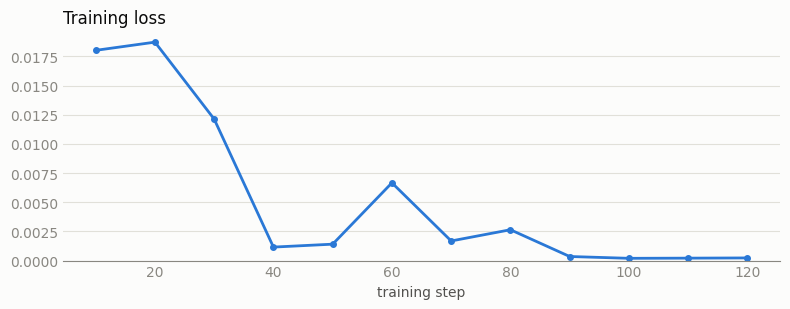

In [11]:
# @title Train, and watch the loss fall { display-mode: "form" }
arguments = TrainingArguments(
    output_dir="lora-output",
    per_device_train_batch_size=2 if SMOKE else 8,
    num_train_epochs=2,
    max_steps=3 if SMOKE else -1,
    learning_rate=2e-4,
    logging_steps=1 if SMOKE else 10,
    fp16=HAS_GPU,
    save_strategy="no",
    report_to="none",
    remove_unused_columns=False,
)
trainer = Trainer(model=model, args=arguments, train_dataset=train_features, data_collator=collate)

start = time.perf_counter()
trainer.train()
training_seconds = time.perf_counter() - start

import matplotlib.pyplot as plt

logged = [entry for entry in trainer.state.log_history if "loss" in entry]
figure, ax = plt.subplots(figsize=(8, 3.2), facecolor=SURFACE)
ax.plot([entry["step"] for entry in logged], [entry["loss"] for entry in logged], color=BLUE, linewidth=2,
        marker="o", markersize=4)
ax.set_title("Training loss", loc="left", color=INK)
ax.set_xlabel("training step", color=SOFT_INK)
ax.set_ylim(bottom=0)
ax.set_facecolor(SURFACE)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=GREY, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GREY)
figure.tight_layout()
plt.show()

big_number(f"{training_seconds / 60:.1f} min", "of training", f"on {gpu_name}")

## 3. Compare to prompting the same model
Four approaches on the same test set:
- the same open model, zero-shot (a prompt only)
- the same open model, few-shot (a prompt plus examples)
- the fine-tuned model
- Claude Haiku, few-shot

In [14]:
# @title Prepare the prompts and the scoring { display-mode: "form" }
FEW_SHOT = "\n".join(
    f"Message: {row['instruction']}\nCategory: {row['category']}"
    for _, row in train.groupby("category").head(1).iterrows()
)


def parse_category(text):
    """Find the first known category in a reply."""
    upper = text.upper()
    found = [(upper.find(category), category) for category in CATEGORIES if category in upper]
    return min(found)[1] if found else "NONE"


def open_model_predict(build_message, messages=None, batch_size=16):
    """Classify messages (the test set by default). Returns the predictions and the seconds taken."""
    messages = list(test["instruction"]) if messages is None else messages
    model.eval()
    predictions = []
    start = time.perf_counter()
    for begin in range(0, len(messages), batch_size):
        texts = [
            tokenizer.apply_chat_template(
                [{"role": "user", "content": build_message(message)}],
                tokenize=False, add_generation_prompt=True,
            )
            for message in messages[begin:begin + batch_size]
        ]
        inputs = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
        with torch.no_grad():
            output = model.generate(**inputs, max_new_tokens=8, do_sample=False)
        replies = tokenizer.batch_decode(output[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)
        predictions += [parse_category(reply) for reply in replies]
    return predictions, time.perf_counter() - start


def zero_shot(message):
    return f"{TASK}\n\nMessage: {message}"


def few_shot(message):
    return f"{TASK}\n\nExamples:\n{FEW_SHOT}\n\nMessage: {message}"


SAMPLE = test["instruction"].iloc[0]


def prompt_tokens(text):
    return len(prompt_ids([{"role": "user", "content": text}]))


def prompt_box(text, folded_part=""):
    folded = (f'<details><summary style="cursor:pointer;color:{BLUE}">the examples ({len(FEW_SHOT.splitlines()) // 2})</summary>'
              f'<div style="white-space:pre-wrap">{html.escape(folded_part)}</div></details>' if folded_part else "")
    return f'<div style="font-family:monospace;font-size:12px;white-space:pre-wrap">{text}{folded}</div>'


side_by_side({
    f"Zero-shot · {prompt_tokens(zero_shot(SAMPLE))} tokens":
        (prompt_box(html.escape(zero_shot(SAMPLE))), BLUE),
    f"Few-shot · {prompt_tokens(few_shot(SAMPLE))} tokens":
        (prompt_box(html.escape(f"{TASK}\n\nExamples:\n"), FEW_SHOT)
         + prompt_box(html.escape(f"\nMessage: {SAMPLE}")), GREY),
})

"Zero-shot · 90 tokensClassify this customer message into one category: ACCOUNT, CANCEL, CONTACT, DELIVERY, FEEDBACK, INVOICE, ORDER, PAYMENT, REFUND, SHIPPING, SUBSCRIPTION. Reply with the category only. Message: I have to check how soon can I expect my parcel, help me","Few-shot · 300 tokensClassify this customer message into one category: ACCOUNT, CANCEL, CONTACT, DELIVERY, FEEDBACK, INVOICE, ORDER, PAYMENT, REFUND, SHIPPING, SUBSCRIPTION. Reply with the category only. Examples: the examples (11)Message: I have an issue with the online registration Category: ACCOUNT Message: I want to locate order {{Order Number}}, could I get some help? Category: ORDER Message: how could I check how long it takes for my parcel to arrive? Category: DELIVERY Message: i need help chanigng the shipping address Category: SHIPPING Message: I need to sign up to the newsletter, how can I do it? Category: SUBSCRIPTION Message: I want to see your payment modalities, can I get some help? Category: PAYMENT Message: seeing invoices from {{Person Name}} Category: INVOICE Message: i cannot speak with a person Category: CONTACT Message: I expect a refund of {{Refund Amount}} dollars, has it been processed? Category: REFUND Message: I want to see the termination fee, help me Category: CANCEL Message: I have to leave a comment for a product, I need assistance Category: FEEDBACK Message: I have to check how soon can I expect my parcel, help me"


### One message, before and after
The same message, the same prompt, to the model without its training and with it.

In [15]:
# @title Try a message: before and after training { display-mode: "form" }
MESSAGE = "I was charged twice for my order, can I get my money back?"  # @param {type:"string"}

with model.disable_adapter():  # The original model, without the trained pieces.
    (before,), _ = open_model_predict(zero_shot, [MESSAGE])
(after,), _ = open_model_predict(zero_shot, [MESSAGE])

def category_badge(category):
    return badge("no valid category", GREY) if category == "NONE" else badge(category)


display(HTML(card("The message", text_html(MESSAGE), GREY)))
side_by_side({
    "Before training": (category_badge(before), GREY),
    "After training": (category_badge(after), BLUE),
})

Before trainingINVOICE,After trainingREFUND


### The whole test set
Now every approach on all the test messages. Accuracy is the share of messages put in the right
category.

In [18]:
# @title Run the open model three ways { display-mode: "form" }
def accuracy(predictions):
    return sum(p == truth for p, truth in zip(predictions, test["category"])) / len(test)


def row(name, predictions, seconds, cost_per_1000):
    return {
        "approach": name,
        "accuracy": accuracy(predictions),
        "ms per ticket": round(1000 * seconds / len(test)),
        "cost per 1,000 tickets": cost_per_1000,
    }


FREE_TIER = "$0"
rows = []

with model.disable_adapter():  # The original model, without the trained pieces.
    predictions, seconds = open_model_predict(zero_shot)
    rows.append(row("Open model, zero-shot", predictions, seconds, FREE_TIER))
    predictions, seconds = open_model_predict(few_shot)
    rows.append(row("Open model, few-shot", predictions, seconds, FREE_TIER))

predictions, seconds = open_model_predict(zero_shot)
rows.append(row("Open model, fine-tuned", predictions, seconds, FREE_TIER))


def show_results(rows):
    """One row per approach, with its accuracy as a bar."""
    body = "".join(
        f'<tr><td style="padding:8px 14px 8px 0;color:{INK};font-weight:600;border-top:1px solid {GRID}">{html.escape(r["approach"])}</td>'
        f'<td style="padding:8px 14px 8px 0;border-top:1px solid {GRID};width:40%">'
        f'<div style="background:{GRID};border-radius:3px"><div style="width:{r["accuracy"]:.0%};background:{BLUE};'
        f'color:#fff;font-size:12px;font-weight:600;padding:2px 6px;border-radius:3px;white-space:nowrap">{r["accuracy"]:.0%}</div></div></td>'
        f'<td style="padding:8px 14px 8px 0;color:{SOFT_INK};text-align:right;border-top:1px solid {GRID}">{r["ms per ticket"]} ms</td>'
        f'<td style="padding:8px 0;color:{SOFT_INK};border-top:1px solid {GRID}">{html.escape(r["cost per 1,000 tickets"])}</td></tr>'
        for r in rows
    )
    header = "".join(
        f'<th style="padding:6px 14px 6px 0;text-align:left;color:{SOFT_INK};font-weight:600">{name}</th>'
        for name in ("approach", "accuracy", "per ticket", "cost per 1,000 tickets")
    )
    display(HTML(f'<table style="border-collapse:collapse;background:#fff;width:100%"><tr>{header}</tr>{body}</table>'))


show_results(rows)

approach,accuracy,per ticket,"cost per 1,000 tickets"
"Open model, zero-shot",42%,47 ms,$0
"Open model, few-shot",38%,82 ms,$0
"Open model, fine-tuned",99%,34 ms,$0


In [17]:
# @title Add Claude Haiku, few-shot { display-mode: "form" }
SMALL_MODEL = "claude-haiku-5-5"
PRICES = (0.10, 0.50)  # Haiku: dollars per million tokens, (input, output).


def claude_predict(message):
    """Classify one message with Claude Haiku. Returns the category and the cost of the call."""
    response = client.messages.create(
        model=SMALL_MODEL,
        max_tokens=12,
        thinking={"type": "disabled"},
        messages=[{"role": "user", "content": few_shot(message)}],
    )
    text = "".join(block.text for block in response.content if block.type == "text")
    cost = (response.usage.input_tokens * PRICES[0] + response.usage.output_tokens * PRICES[1]) / 1_000_000
    return parse_category(text), cost, response.usage.input_tokens, response.usage.output_tokens


start = time.perf_counter()
with ThreadPoolExecutor(max_workers=4) as pool:  # Four calls at a time.
    results = list(pool.map(claude_predict, test["instruction"]))
seconds = time.perf_counter() - start



approach,accuracy,per ticket,"cost per 1,000 tickets"
"Open model, zero-shot",42%,23 ms,$0 API (free T4)
"Open model, few-shot",38%,50 ms,$0 API (free T4)
"Open model, fine-tuned",99%,25 ms,$0 API (free T4)
"Claude Haiku, few-shot",92%,138 ms,$0.05


In [19]:
predictions = [category for category, *_ in results]
cost_per_1000 = sum(cost for _, cost, *_ in results) * 1000 / len(test)
rows.append(row("Claude Haiku, few-shot", predictions, seconds, f"${cost_per_1000:.2f}"))

display(HTML(name_label("Claude model", SMALL_MODEL, "https://docs.claude.com/en/docs/about-claude/models/overview")))
show_results(rows)
tokens_in, tokens_out = sum(r[2] for r in results), sum(r[3] for r in results)
display(HTML(f'<div style="color:{SOFT_INK};font-size:13px;margin-top:6px">Claude, for the {len(test)} test messages: '
             f"{tokens_in:,} tokens in · {tokens_out:,} out</div>"))

approach,accuracy,per ticket,"cost per 1,000 tickets"
"Open model, zero-shot",42%,47 ms,$0
"Open model, few-shot",38%,82 ms,$0
"Open model, fine-tuned",99%,34 ms,$0
"Claude Haiku, few-shot",92%,34 ms,$0.05
